# Grafikai po pagerinimo

Painiavos matricos, poslinkis pagal tikrąjį balą ir klaidų kryptis naujiems modeliams.
Balų ašis yra 3…9. Praktinės klasės: žema (≤4), vidutinė (5–6), aukšta (≥7).

In [1]:
from pathlib import Path
import sys
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "winequality").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

CANDIDATES = [
    ROOT / "results" / "pagerinta",
    ROOT / "results" / "palyginimas",
    ROOT / "results",
    ROOT / "results" / "smoke",
]
RESULTS = next(path for path in CANDIDATES if (path / "comparison.csv").exists())
ORDER = ["mean", "linear", "cat_asym", "cat_ordinal", "lgbm_ordinal"]
LABELS = {
    "mean": "Vidurkis",
    "linear": "Tiesinė, nauji požymiai",
    "cat_asym": "CatBoost asimetrinis",
    "cat_ordinal": "CatBoost ordinalinis",
    "lgbm_ordinal": "LightGBM ordinalinis",
    "xgb_ordinal": "XGBOrdinal (ankstesnis)",
    "catboost": "CatBoost (ankstesnis)",
}
WINE = {"red": "raudonas", "white": "baltas"}
COLORS = {
    "mean": "#7f7f7f",
    "linear": "#4c78a8",
    "cat_asym": "#e45756",
    "cat_ordinal": "#54a24b",
    "lgbm_ordinal": "#f58518",
    "xgb_ordinal": "#b279a2",
    "catboost": "#9d755d",
}
PREVIOUS_PATH = ROOT / "results" / "palyginimas" / "comparison.csv"
PREVIOUS_METRICS_PATH = ROOT / "results" / "palyginimas" / "metrics.json"
previous = pd.read_csv(PREVIOUS_PATH) if PREVIOUS_PATH.exists() else None
previous_metrics = json.loads(PREVIOUS_METRICS_PATH.read_text(encoding="utf-8")) if PREVIOUS_METRICS_PATH.exists() else None
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

comparison = pd.read_csv(RESULTS / "comparison.csv")
metrics = json.loads((RESULTS / "metrics.json").read_text(encoding="utf-8"))
comparison["model"] = pd.Categorical(comparison["model"], ORDER, ordered=True)
comparison = comparison.sort_values(["wine", "model"]).reset_index(drop=True)
print("Rezultatai:", RESULTS)
print("Protokolas:", metrics.get("protocol"), "| pasirinktas modelis:", metrics.get("selected_model"))

Rezultatai: C:\Users\marci\Desktop\uni stuff\Magistras\1 sem\IS\IS_Egzaminas\results\pagerinta
Protokolas: pagerinta | pasirinktas modelis: lgbm_ordinal


## 7×7 balų painiavos matricos

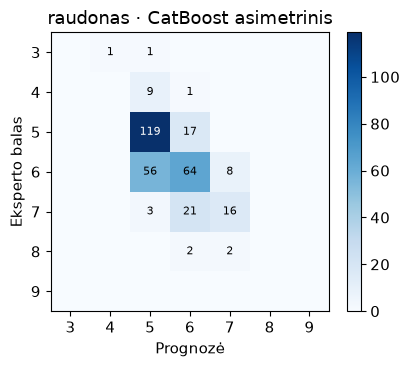

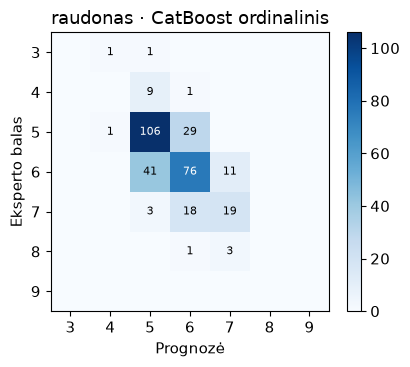

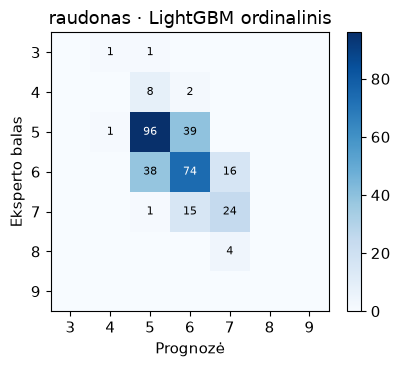

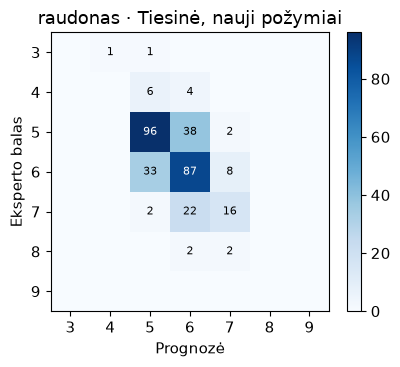

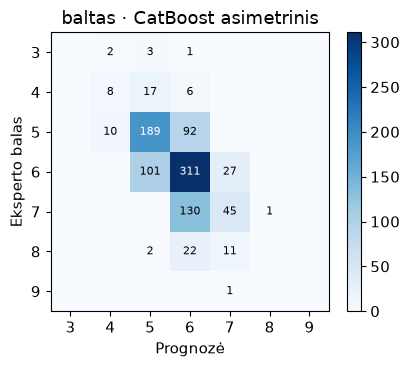

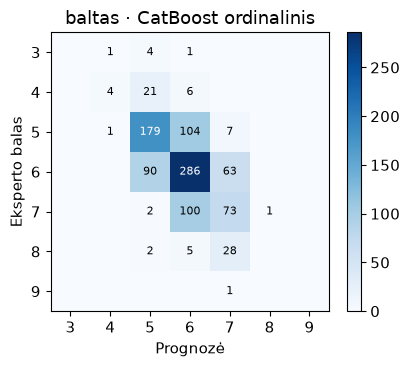

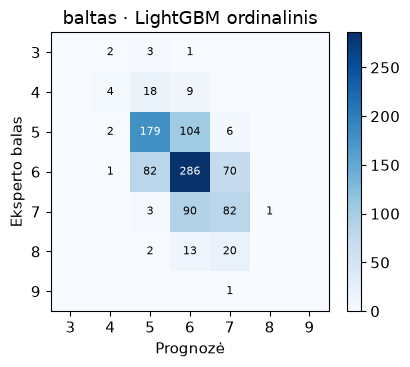

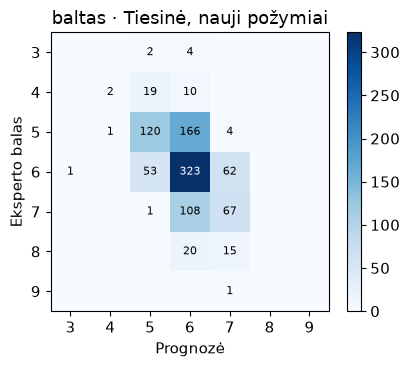

In [2]:
def draw_confusion(matrix, title, labels):
    matrix = np.asarray(matrix, dtype=float)
    fig, ax = plt.subplots(figsize=(4.4, 3.8))
    image = ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(range(len(labels)), labels)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("Prognozė")
    ax.set_ylabel("Eksperto balas")
    ax.set_title(title)
    limit = matrix.max() if matrix.max() > 0 else 1
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = int(matrix[i, j])
            if value == 0:
                continue
            ax.text(j, i, str(value), ha="center", va="center", color="white" if matrix[i, j] > limit * 0.55 else "black", fontsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046)
    fig.tight_layout()
    return fig

score_labels = [str(rank) for rank in range(3, 10)]
class_labels = ["žema", "vidutinė", "aukšta"]
focus = [name for name in ["cat_asym", "cat_ordinal", "lgbm_ordinal", "linear"] if name in set(comparison["model"].astype(str))]
wines = [wine for wine in ["red", "white"] if wine in metrics["per_wine"]]
for wine in wines:
    for name in focus:
        draw_confusion(
            metrics["per_wine"][wine]["metrics"][name]["confusion_score"],
            f"{WINE[wine]} · {LABELS[name]}",
            score_labels,
        )
        plt.show()

## 3×3 praktinių klasių painiava

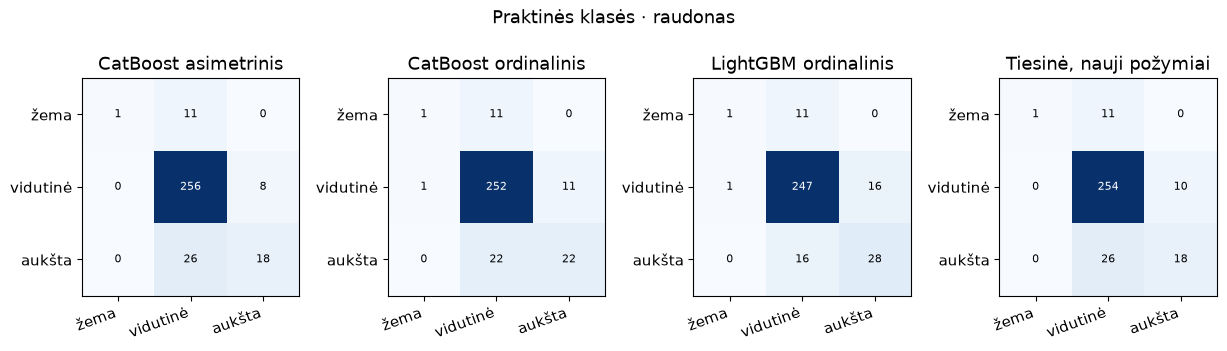

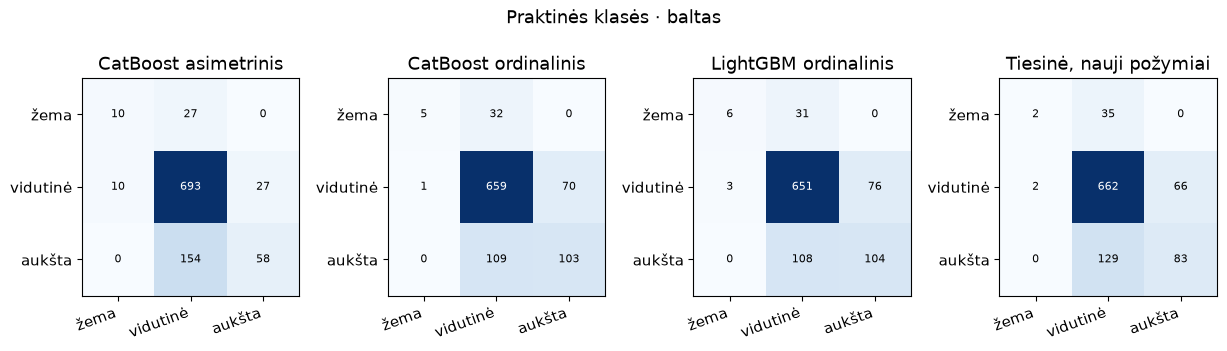

In [3]:
for wine in wines:
    fig, axes = plt.subplots(1, len(focus), figsize=(3.1 * len(focus), 3.3))
    if len(focus) == 1:
        axes = [axes]
    for ax, name in zip(axes, focus):
        matrix = np.asarray(metrics["per_wine"][wine]["metrics"][name]["confusion_class"], dtype=float)
        ax.imshow(matrix, cmap="Blues")
        ax.set_xticks(range(3), class_labels, rotation=20, ha="right")
        ax.set_yticks(range(3), class_labels)
        ax.set_title(LABELS[name])
        limit = matrix.max() if matrix.max() > 0 else 1
        for i in range(3):
            for j in range(3):
                value = int(matrix[i, j])
                ax.text(j, i, str(value), ha="center", va="center", fontsize=8, color="white" if matrix[i, j] > limit * 0.55 else "black")
    fig.suptitle(f"Praktinės klasės · {WINE[wine]}", y=1.02)
    fig.tight_layout()
    plt.show()

## MAE pagal tikrąjį balą

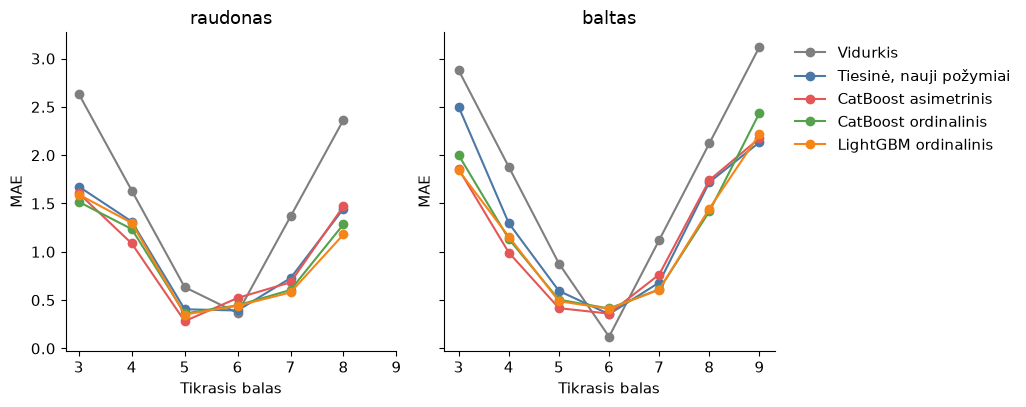

In [4]:
fig, axes = plt.subplots(1, len(wines), figsize=(5.2 * len(wines), 4.2), sharey=True)
if len(wines) == 1:
    axes = [axes]
for ax, wine in zip(axes, wines):
    for name in ORDER:
        bias = metrics["per_wine"][wine]["metrics"][name]["bias_by_score"]
        ranks = sorted(int(key) for key in bias)
        ax.plot(ranks, [bias[str(rank)]["mae"] for rank in ranks], marker="o", label=LABELS[name], color=COLORS[name])
    ax.set_title(WINE[wine])
    ax.set_xlabel("Tikrasis balas")
    ax.set_ylabel("MAE")
    ax.set_xticks(range(3, 10))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[-1].legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

## Kraštų poslinkis, palyginti su ankstesniu CatBoost

In [5]:
def tail_bias(bias):
    values = []
    for rank in ["3", "4", "7", "8"]:
        if rank in bias:
            values.append(abs(bias[rank]["bias"]))
    return float(np.mean(values)) if values else np.nan

if previous_metrics is not None:
    rows = []
    for wine in wines:
        old = previous_metrics["per_wine"][wine]["metrics"]["catboost"]["bias_by_score"]
        rows.append({"Vynas": WINE[wine], "Modelis": LABELS["catboost"], "vidutinis |poslinkis| kraštuose": tail_bias(old)})
        for name in ["cat_asym", "cat_ordinal", "lgbm_ordinal"]:
            bias = metrics["per_wine"][wine]["metrics"][name]["bias_by_score"]
            rows.append({"Vynas": WINE[wine], "Modelis": LABELS[name], "vidutinis |poslinkis| kraštuose": tail_bias(bias)})
    pd.DataFrame(rows).round(3)

## Pervertinimas ir nuvertinimas

In [6]:
rows = []
for wine in wines:
    for name in ORDER:
        direction = metrics["per_wine"][wine]["metrics"][name]["error_direction"]
        rows.append({
            "Vynas": WINE[wine],
            "Modelis": LABELS[name],
            "Tikslu": direction["exact"],
            "Pervertinta": direction["overestimate"],
            "Nuvertinta": direction["underestimate"],
            "|klaida| ≥ 2": direction["critical_abs_ge_2"],
        })
direction_table = pd.DataFrame(rows)
direction_table

,Vynas,Modelis,Tikslu,Pervertinta,Nuvertinta,|klaida| ≥ 2
0,raudonas,Vidurkis,128,148,44,16
1,raudonas,"Tiesinė, nauji požymiai",199,60,61,11
2,raudonas,CatBoost asimetrinis,199,37,84,7
3,raudonas,CatBoost ordinalinis,201,52,67,6
4,raudonas,LightGBM ordinalinis,194,67,59,4
5,baltas,Vidurkis,439,328,212,73
6,baltas,"Tiesinė, nauji požymiai",512,267,200,43
7,baltas,CatBoost asimetrinis,553,149,277,35
8,baltas,CatBoost ordinalinis,542,208,229,28
9,baltas,LightGBM ordinalinis,551,214,214,39


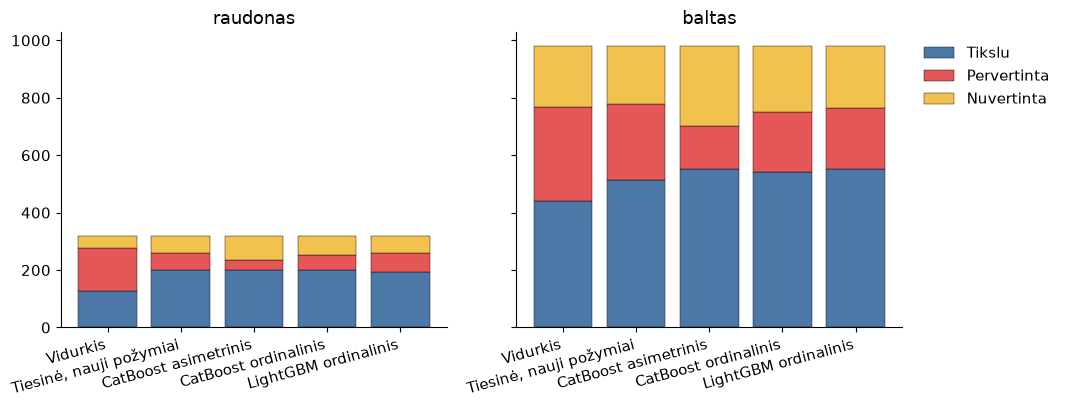

In [7]:
fig, axes = plt.subplots(1, len(wines), figsize=(5.4 * len(wines), 4.2), sharey=True)
if len(wines) == 1:
    axes = [axes]
parts = ["Tikslu", "Pervertinta", "Nuvertinta"]
palette = ["#4c78a8", "#e45756", "#f2c14e"]
for ax, wine in zip(axes, wines):
    part = direction_table[direction_table["Vynas"] == WINE[wine]]
    x = np.arange(len(ORDER))
    bottom = np.zeros(len(ORDER))
    for column, color in zip(parts, palette):
        height = part[column].to_numpy()
        ax.bar(x, height, bottom=bottom, label=column, color=color, edgecolor="black", linewidth=0.3)
        bottom = bottom + height
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS[name] for name in ORDER], rotation=15, ha="right")
    ax.set_title(WINE[wine])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[-1].legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

## Didžiausios absoliučios klaidos

In [8]:
frames = []
for path in sorted(RESULTS.glob("error_examples_*.csv")):
    frame = pd.read_csv(path)
    frame.insert(0, "Vynas", WINE.get(path.stem.replace("error_examples_", ""), path.stem))
    frames.append(frame)
if frames:
    examples = pd.concat(frames, ignore_index=True)
    examples.round(3)
else:
    print("Klaidų pavyzdžių failų nėra.")